# Памперсы или пиво? Рекомендательная система Amazon

## Библиотеки

In [2]:
%matplotlib inline
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares
from lightfm import LightFM
from lightfm.data import Dataset as LFMDataset
from replay.metrics import HitRate, MRR, NDCG, Coverage, Experiment
from tqdm import tqdm
from IPython.display import display

USER_COL = 'user_id'
ITEM_COL = 'item_id'
EXP_RATING_COL = 'rating'
TIMESTAMP = 'start_date'
SEED = 42
K = 10

np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (12, 4)
pd.set_option('display.max_columns', 20)

Matplotlib is building the font cache; this may take a moment.


/private/tmp/otus-recsys-venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/private/tmp/otus-recsys-venv/lib/python3.11/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


## Данные

In [3]:
data_dir = Path('recomendation/data') if Path('recomendation').is_dir() else Path('data')
data_dir.mkdir(parents=True, exist_ok=True)
file = data_dir / 'Industrial_and_Scientific_5.json.gz'
url = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Industrial_and_Scientific_5.json.gz'

if not file.exists():
    urlretrieve(url, file)

df = pd.read_json(file, lines=True)[['reviewerID', 'asin', 'overall', 'unixReviewTime']]
df = df.rename(columns={
    'reviewerID': USER_COL, 'asin': ITEM_COL,
    'overall': EXP_RATING_COL, 'unixReviewTime': TIMESTAMP
})
df[TIMESTAMP] = pd.to_datetime(df[TIMESTAMP], unit='s')
df.head()

,user_id,item_id,rating,start_date
0,A1JB7HFWHRYHT7,B0000223SI,5,2017-11-27
1,A2FCLJG5GV8SD6,B0000223SI,5,2017-11-04
2,A3IT9B33NWYQSL,B0000223SI,5,2017-10-27
3,AUL5LCV4TT73P,B0000223SK,4,2018-01-13
4,A1V3I3L5JKO7TM,B0000223SK,5,2017-10-07


In [4]:
df.info()
display(df.isna().sum().rename('Пропуски'))
print('Повторы пользователь — товар:', df.duplicated([USER_COL, ITEM_COL]).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77071 entries, 0 to 77070
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     77071 non-null  object        
 1   item_id     77071 non-null  object        
 2   rating      77071 non-null  int64         
 3   start_date  77071 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 2.4+ MB


user_id       0
item_id       0
rating        0
start_date    0
Name: Пропуски, dtype: int64

Повторы пользователь — товар: 5046


In [5]:
n_raw = len(df)
df = df.dropna(subset=[USER_COL, ITEM_COL, EXP_RATING_COL, TIMESTAMP])
df = df.sort_values(TIMESTAMP, kind='stable').drop_duplicates([USER_COL, ITEM_COL], keep='last')
df = df.reset_index(drop=True)
print('Удалено записей:', n_raw - len(df))

Удалено записей: 5046


## EDA

In [6]:
n_users = df[USER_COL].nunique()
n_items = df[ITEM_COL].nunique()
user_groups = df.groupby(USER_COL)[ITEM_COL].count()
item_groups = df.groupby(ITEM_COL)[USER_COL].count()

display(pd.Series({
    'Взаимодействий': len(df),
    'Пользователей': n_users,
    'Товаров': n_items,
    'Средний рейтинг': df[EXP_RATING_COL].mean(),
    'Медиана действий пользователя': user_groups.median(),
    'Медиана отзывов на товар': item_groups.median(),
    'Разреженность, %': 100 * (1 - len(df) / (n_users * n_items))
}).to_frame('Значение').round(3))
print('Период:', df[TIMESTAMP].min().date(), '—', df[TIMESTAMP].max().date())

,Значение
Взаимодействий,72025.000
Пользователей,11041.000
Товаров,5334.000
Средний рейтинг,4.523
Медиана действий пользователя,6.000
Медиана отзывов на товар,8.000
"Разреженность, %",99.878


Период: 2003-04-27 — 2018-09-28


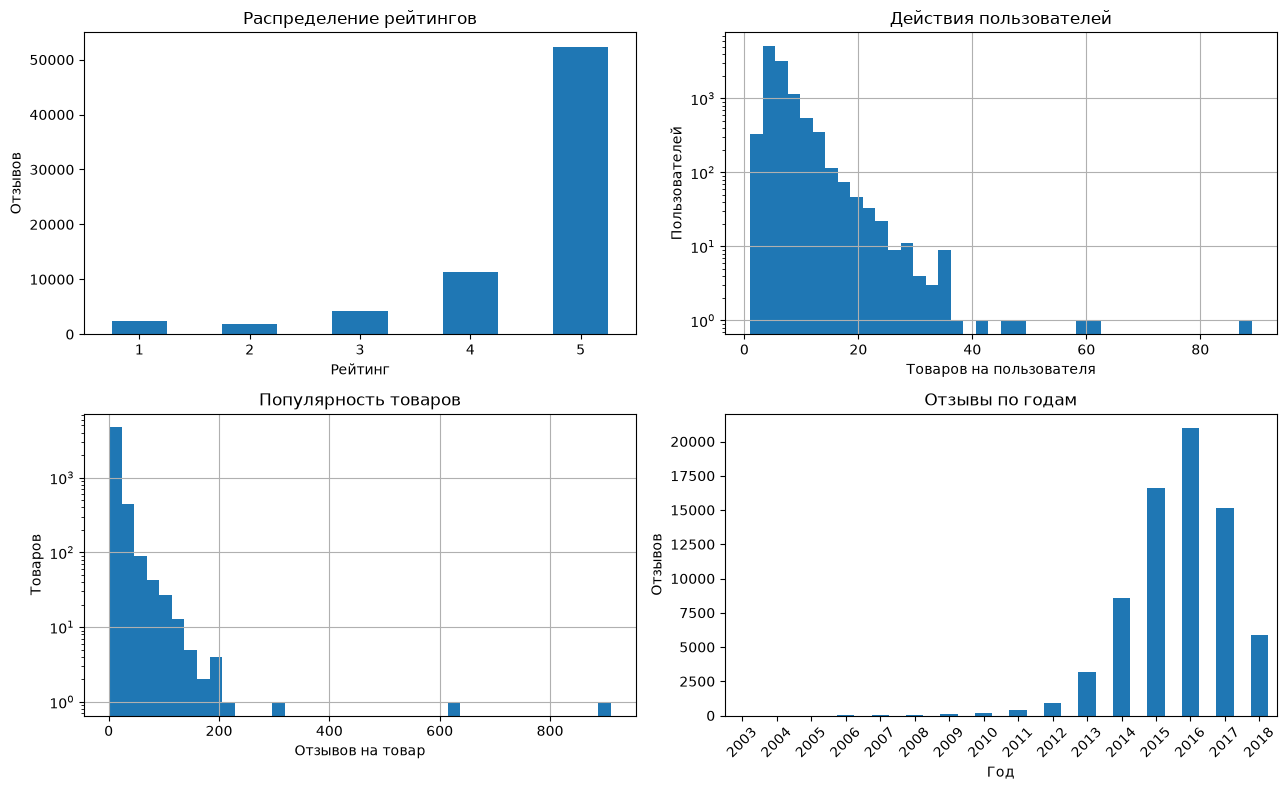

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
df[EXP_RATING_COL].value_counts().sort_index().plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title='Распределение рейтингов', xlabel='Рейтинг', ylabel='Отзывов')
user_groups.hist(bins=40, ax=axes[0, 1])
axes[0, 1].set(title='Действия пользователей', xlabel='Товаров на пользователя', ylabel='Пользователей', yscale='log')
item_groups.hist(bins=40, ax=axes[1, 0])
axes[1, 0].set(title='Популярность товаров', xlabel='Отзывов на товар', ylabel='Товаров', yscale='log')
df.groupby(df[TIMESTAMP].dt.year).size().plot.bar(ax=axes[1, 1], rot=45)
axes[1, 1].set(title='Отзывы по годам', xlabel='Год', ylabel='Отзывов')
plt.tight_layout()
plt.show()

In [8]:
display(pd.concat([
    user_groups.describe().rename('Товаров у пользователя'),
    item_groups.describe().rename('Отзывов на товар')
], axis=1).round(2))
display(item_groups.nlargest(10).rename('Отзывов').to_frame())
print(f'Доля оценок 4–5: {df[EXP_RATING_COL].ge(4).mean():.1%}')
print(f'Доля отзывов у топ-10 товаров: {item_groups.nlargest(10).sum() / len(df):.1%}')

,Товаров у пользователя,Отзывов на товар
count,11041.00,5334.00
mean,6.52,13.50
std,3.40,22.33
min,1.00,1.00
25%,5.00,6.00
50%,6.00,8.00
75%,7.00,14.00
max,89.00,910.00


,Отзывов
item_id,
B00DRALJ28,910
B0013BKDO8,615
B000EJUBBU,303
B0001MSC84,210
B00837ZGRY,204
B00DMI632G,203
B0002EQU6C,201
B005IQTSE0,188
B00J0GMMP6,165


Доля оценок 4–5: 88.5%
Доля отзывов у топ-10 товаров: 4.4%


## Подготовка и leave-one-out

In [9]:
df_implicit = df[df[EXP_RATING_COL] >= 4].copy()
counts = df_implicit.groupby(USER_COL)[ITEM_COL].transform('count')
df_implicit = df_implicit[counts >= 3].copy()
print('Положительных взаимодействий:', len(df_implicit))
print('Пользователей:', df_implicit[USER_COL].nunique())
print('Товаров:', df_implicit[ITEM_COL].nunique())

Положительных взаимодействий: 62781
Пользователей: 10431
Товаров: 5316


In [10]:
def leave_one_out(interactions):
    interactions = interactions.sort_values([USER_COL, TIMESTAMP, ITEM_COL])
    test = interactions.groupby(USER_COL, sort=False).tail(1)
    train = interactions.drop(test.index)
    return train.reset_index(drop=True), test.reset_index(drop=True)

train, test = leave_one_out(df_implicit)

assert len(train) + len(test) == len(df_implicit)
assert test.groupby(USER_COL).size().eq(1).all()
assert set(test[USER_COL]) == set(train[USER_COL])
assert train.merge(test, on=[USER_COL, ITEM_COL]).empty
assert train.groupby(USER_COL)[TIMESTAMP].max().le(test.set_index(USER_COL)[TIMESTAMP]).all()

display(pd.DataFrame({
    'Взаимодействий': [len(train), len(test)],
    'Пользователей': [train[USER_COL].nunique(), test[USER_COL].nunique()],
    'Товаров': [train[ITEM_COL].nunique(), test[ITEM_COL].nunique()]
}, index=['train', 'test']))
cold_items = ~test[ITEM_COL].isin(train[ITEM_COL])
print(f'Тестовых взаимодействий с новыми товарами: {cold_items.sum()} ({cold_items.mean():.2%})')

,Взаимодействий,Пользователей,Товаров
train,52350,10431,5298
test,10431,10431,3574


Тестовых взаимодействий с новыми товарами: 29 (0.28%)


In [11]:
train['uid'], user_uniques = pd.factorize(train[USER_COL], sort=True)
train['iid'], item_uniques = pd.factorize(train[ITEM_COL], sort=True)
id2user = dict(enumerate(user_uniques))
id2item = dict(enumerate(item_uniques))
user2id = {u: i for i, u in id2user.items()}
item2id = {it: j for j, it in id2item.items()}

test['uid'] = test[USER_COL].map(user2id)
test_users = np.sort(test['uid'].unique())
all_items = np.arange(len(item_uniques), dtype=np.int32)

train_sparse = csr_matrix(
    (np.ones(len(train), dtype=np.float32), (train['uid'], train['iid'])),
    shape=(len(user_uniques), len(item_uniques))
)
assert train_sparse.nnz == len(train)
assert (len(item_uniques) - np.diff(train_sparse.indptr) >= K).all()
print('Матрица:', train_sparse.shape)
print(f'Разреженность: {1 - train_sparse.nnz / np.prod(train_sparse.shape):.3%}')

Матрица: (10431, 5298)
Разреженность: 99.905%


## Модели

In [12]:
def get_recs(score_function, name, k=K):
    rows = []
    for uid in tqdm(test_users, desc=name):
        scores = np.asarray(score_function(int(uid)), dtype=np.float64).copy()
        scores[train_sparse[uid].indices] = -np.inf
        ids = np.argsort(-scores, kind='stable')[:k]
        rows.extend((uid, iid, scores[iid], rank)
                    for rank, iid in enumerate(ids, start=1))

    recs = pd.DataFrame(rows, columns=['uid', 'iid', 'score', 'rank'])
    recs[USER_COL] = recs['uid'].map(id2user)
    recs[ITEM_COL] = recs['iid'].map(id2item)
    recs['rank_score'] = -recs['rank']
    return recs[[USER_COL, ITEM_COL, 'score', 'rank', 'rank_score']]

### Popularity

In [13]:
popularity = np.asarray(train_sparse.sum(axis=0)).ravel()
recs_pop = get_recs(lambda uid: popularity, 'Popularity')
recs_pop.head(10)


Popularity:   0%|          | 0/10431 [00:00<?, ?it/s]


Popularity:   5%|▍         | 473/10431 [00:00<00:02, 4720.05it/s]


Popularity:   9%|▉         | 954/10431 [00:00<00:01, 4767.51it/s]


Popularity:  14%|█▍        | 1439/10431 [00:00<00:01, 4802.96it/s]


Popularity:  18%|█▊        | 1925/10431 [00:00<00:01, 4822.15it/s]

...


Popularity:  88%|████████▊ | 9225/10431 [00:01<00:00, 4834.92it/s]


Popularity:  93%|█████████▎| 9714/10431 [00:02<00:00, 4849.90it/s]


Popularity:  98%|█████████▊| 10204/10431 [00:02<00:00, 4863.13it/s]


Popularity: 100%|██████████| 10431/10431 [00:02<00:00, 4824.42it/s]

,user_id,item_id,score,rank,rank_score
0,A0096681Y127OL1H8W3U,B00DRALJ28,520.0,1,-1
1,A0096681Y127OL1H8W3U,B0013BKDO8,516.0,2,-2
2,A0096681Y127OL1H8W3U,B000EJUBBU,242.0,3,-3
3,A0096681Y127OL1H8W3U,B0002EQU6C,178.0,4,-4
4,A0096681Y127OL1H8W3U,B005IQTSE0,163.0,5,-5
5,A0096681Y127OL1H8W3U,B00DMI632G,148.0,6,-6
6,A0096681Y127OL1H8W3U,B00837ZGRY,145.0,7,-7
7,A0096681Y127OL1H8W3U,B00J0GMMP6,141.0,8,-8
8,A0096681Y127OL1H8W3U,B0006O1ICE,140.0,9,-9
9,A0096681Y127OL1H8W3U,B00J0GPC80,128.0,10,-10


### ALS

In [14]:
%%time
algo = AlternatingLeastSquares(
    factors=50,
    regularization=0.1,
    alpha=20,
    iterations=30,
    use_gpu=False,
    num_threads=1,
    random_state=SEED
)
algo.fit(train_sparse, show_progress=False)
recs_als = get_recs(lambda uid: algo.item_factors @ algo.user_factors[uid], 'ALS')


ALS:   0%|          | 0/10431 [00:00<?, ?it/s]


ALS:   4%|▎         | 387/10431 [00:00<00:02, 3860.58it/s]


ALS:   7%|▋         | 776/10431 [00:00<00:02, 3877.78it/s]


ALS:  11%|█         | 1166/10431 [00:00<00:02, 3885.60it/s]


ALS:  15%|█▍        | 1555/10431 [00:00<00:02, 3887.26it/s]

...


ALS:  90%|█████████ | 9390/10431 [00:02<00:00, 3886.04it/s]


ALS:  94%|█████████▍| 9781/10431 [00:02<00:00, 3890.28it/s]


ALS:  98%|█████████▊| 10174/10431 [00:02<00:00, 3901.93it/s]


ALS: 100%|██████████| 10431/10431 [00:02<00:00, 3900.92it/s]

CPU times: user 3.32 s, sys: 24.4 ms, total: 3.34 s
Wall time: 3.36 s


### LightFM

In [15]:
lfm_dataset = LFMDataset()
lfm_dataset.fit(users=range(len(user_uniques)), items=range(len(item_uniques)))
interactions, _ = lfm_dataset.build_interactions(
    train[['uid', 'iid']].itertuples(index=False, name=None)
)
assert (interactions.tocsr() != train_sparse).nnz == 0

In [16]:
%%time
lightfm = LightFM(no_components=50, loss='warp', learning_rate=0.05, random_state=SEED)
lightfm.fit(interactions, epochs=40, num_threads=1)
recs_lfm = get_recs(
    lambda uid: lightfm.predict(uid, all_items, num_threads=1), 'LightFM'
)


LightFM:   0%|          | 0/10431 [00:00<?, ?it/s]


LightFM:   3%|▎         | 281/10431 [00:00<00:03, 2805.29it/s]


LightFM:   5%|▌         | 562/10431 [00:00<00:03, 2792.03it/s]


LightFM:   8%|▊         | 844/10431 [00:00<00:03, 2800.65it/s]


LightFM:  11%|█         | 1127/10431 [00:00<00:03, 2808.40it/s]

...


LightFM:  94%|█████████▍| 9830/10431 [00:03<00:00, 2798.33it/s]


LightFM:  97%|█████████▋| 10111/10431 [00:03<00:00, 2799.18it/s]


LightFM: 100%|█████████▉| 10392/10431 [00:03<00:00, 2799.49it/s]


LightFM: 100%|██████████| 10431/10431 [00:03<00:00, 2796.44it/s]

CPU times: user 4.33 s, sys: 22.9 ms, total: 4.35 s
Wall time: 4.35 s


## Оценка качества

Для каждого пользователя в test один релевантный товар. Если он на позиции r ≤ 10,
HR@10 = 1, MRR@10 = 1/r, NDCG@10 = 1/log2(r+1); иначе все три метрики равны 0.
Результат усредняем по всем пользователям test.
Coverage@10 — доля уникальных рекомендованных товаров от всего каталога train.

In [17]:
recommendations = {'Popularity': recs_pop, 'ALS': recs_als, 'LightFM': recs_lfm}
for name, recs in recommendations.items():
    assert set(recs[USER_COL]) == set(test[USER_COL]), name
    assert recs.groupby(USER_COL).size().eq(K).all(), name
    assert not recs.duplicated([USER_COL, ITEM_COL]).any(), name
    assert recs.merge(train[[USER_COL, ITEM_COL]], on=[USER_COL, ITEM_COL]).empty, name
    assert np.isfinite(recs['score']).all(), name

metrics = Experiment(
    [HitRate([K]), MRR([K]), NDCG([K]), Coverage([K])],
    test[[USER_COL, ITEM_COL]],
    train[[USER_COL, ITEM_COL]],
    query_column=USER_COL,
    item_column=ITEM_COL,
    rating_column='rank_score'
)
for name, recs in recommendations.items():
    metrics.add_result(name, recs)

results = metrics.results.rename(columns={'HitRate@10': 'HR@10'})
results = results[['HR@10', 'MRR@10', 'NDCG@10', 'Coverage@10']]
results = results.sort_values('NDCG@10', ascending=False)
display(results.round(4))

,HR@10,MRR@10,NDCG@10,Coverage@10
ALS,0.1068,0.0630,0.0733,0.2427
LightFM,0.0906,0.0516,0.0607,0.7799
Popularity,0.0393,0.0264,0.0293,0.0028


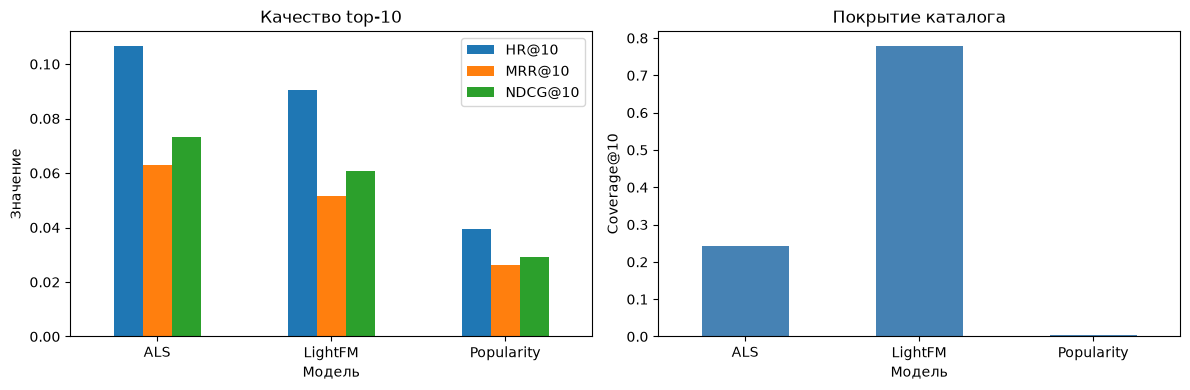

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results[['HR@10', 'MRR@10', 'NDCG@10']].plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Качество top-10', xlabel='Модель', ylabel='Значение')
results['Coverage@10'].plot.bar(ax=axes[1], rot=0, color='steelblue')
axes[1].set(title='Покрытие каталога', xlabel='Модель', ylabel='Coverage@10')
plt.tight_layout()
plt.show()

### Пример рекомендаций

In [19]:
example_user = test.iloc[0][USER_COL]
print('Пользователь:', example_user)
display(train.loc[train[USER_COL] == example_user, [ITEM_COL, EXP_RATING_COL, TIMESTAMP]])
print('Отложенный товар:', test.loc[test[USER_COL] == example_user, ITEM_COL].iloc[0])
display(pd.concat({
    name: recs.loc[recs[USER_COL] == example_user, [ITEM_COL, 'score', 'rank']].reset_index(drop=True)
    for name, recs in recommendations.items()
}, names=['Модель', 'Строка']))

Пользователь: A0096681Y127OL1H8W3U


,item_id,rating,start_date
0,B00E8JOCOE,5,2015-06-24
1,B00S730YWG,5,2015-06-24


Отложенный товар: B0098MLBAO


item_id       score  rank
Модель     Строка                              
Popularity 0       B00DRALJ28  520.000000     1
           1       B0013BKDO8  516.000000     2
           2       B000EJUBBU  242.000000     3
           3       B0002EQU6C  178.000000     4
           4       B005IQTSE0  163.000000     5
           5       B00DMI632G  148.000000     6
           6       B00837ZGRY  145.000000     7
           7       B00J0GMMP6  141.000000     8
           8       B0006O1ICE  140.000000     9
           9       B00J0GPC80  128.000000    10
ALS        0       B001E5ZWT4    0.247830     1
           1       B002BBGTK6    0.222258     2
           2       B00CVHIJDK    0.216540     3
           3       B00JZ18K20    0.202275     4
           4       B00K5QVBCU    0.194682     5
           5       B004NG8V9E    0.189781     6
           6       B00BL8BNII    0.186465     7
           7       B00004WCCP    0.185320     8
           8       B00JA3BMDW    0.183504     9
           9       B01FL49VZE    0.182148    10
LightFM    0       B00EUGCT22    1.129810     1
           1       B0002T6L5M    1.105556     2
           2       B004C12Q46    1.075730     3
           3       B00O9JNY9W    1.071112     4
           4       B0000DH8I8    1.055958     5
           5       B001DDWQ4Q    1.021974     6
           6       B007Y7I8AG    1.011961     7
           7       B003DKQB02    0.979627     8
           8       B0013BKDO8    0.970519     9
           9       B0013HT2QW    0.943575    10

## Выводы

In [20]:
best = results.index[0]
baseline = results.loc['Popularity', 'NDCG@10']
delta = results.loc[best, 'NDCG@10'] - baseline
print(f'Лучшая модель по NDCG@10: {best}.')
print(f'HR@10 = {results.loc[best, "HR@10"]:.4f}, '
      f'MRR@10 = {results.loc[best, "MRR@10"]:.4f}, '
      f'NDCG@10 = {results.loc[best, "NDCG@10"]:.4f}.')
print(f'Изменение NDCG@10 относительно Popularity: {delta:+.4f}.')
print(f'Попаданий в top-10: {round(results.loc[best, "HR@10"] * len(test))} из {len(test)}.')
print(f'Максимальное покрытие: {results["Coverage@10"].idxmax()} '
      f'({results["Coverage@10"].max():.1%} каталога).')

Лучшая модель по NDCG@10: ALS.
HR@10 = 0.1068, MRR@10 = 0.0630, NDCG@10 = 0.0733.
Изменение NDCG@10 относительно Popularity: +0.0439.
Попаданий в top-10: 1114 из 10431.
Максимальное покрытие: LightFM (78.0% каталога).


После удаления повторов осталось 72 025 взаимодействий, 11 041 пользователь и 5 334 товара.
88,5% оценок — 4–5; матрица разрежена на 99,878%. Большинство пользователей имеют короткую
историю, а популярность товаров распределена неравномерно.

ALS — лучшая модель при выбранных настройках: HR@10 = 0,1068, MRR@10 = 0,0630,
NDCG@10 = 0,0733. Она нашла отложенный товар у 1 114 из 10 431 пользователей.
NDCG@10 примерно в 2,5 раза выше Popularity. Персонализация заметно улучшила качество.

LightFM уступает ALS по всем трём метрикам точности, но покрывает 78,0% каталога
против 24,3% у ALS. Popularity покрывает только 0,28%: выдаёт почти всем один набор популярных
товаров. Для точности в этом эксперименте выберем ALS; у LightFM больше охват каталога.

Результат относится к выбранной 5-core категории и пользователям с тремя положительными
взаимодействиями. Отзывы служат приближением интереса, оценки ниже 4 не моделируются.
29 новых товаров в test учтены как промахи. Разбиение по пользователям не имитирует общую
временную границу запуска сервиса. 
